# Практика 3 — Сравнение моделей и подбор гиперпараметров
## Hotel Booking Demand

**Assignment 4** · Азиз Абдулин · повтор практики курса по сравнению моделей и подбору гиперпараметров на новом датасете.

Пять семейств моделей на тех же 34 признаках и с тем же разбиением по времени, что в практике 2: логистическая
регрессия, дерево решений, случайный лес, LightGBM и CatBoost. Каждая модель оценивается **с настройками по умолчанию и
после подбора**: перебор по сетке для маленьких пространств (логистическая регрессия, дерево), случайный поиск для леса
и байесовская оптимизация Optuna для двух бустингов. Подбор оценивается на периоде validation (январь–апрель 2017) по
PR-AUC; тестовый период (май–август 2017) открывается один раз в конце.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, PredefinedSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

warnings.filterwarnings("ignore"); optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
DATA, FIG, RES = Path("data"), Path("figures"), Path("results")
F = json.load(open(RES / "p1_features.json"))
NUM, BIN, CAT, Y = F["num"], F["bin"], F["cat"], F["target"]
X = NUM + BIN + CAT
df = pd.read_parquet(DATA / "hotels_clean.parquet").sort_values("arrival_date", kind="stable").reset_index(drop=True)
for c in CAT:                                   # one category list for all periods, learnt on train
    df[c] = pd.Categorical(df[c], categories=sorted(df.loc[df.split == "train", c].unique()))
tr, va, te = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
y_tr, y_va, y_te = tr[Y].to_numpy(), va[Y].to_numpy(), te[Y].to_numpy()
trva, ps = pd.concat([tr, va]), PredefinedSplit(np.r_[np.full(len(tr), -1), np.zeros(len(va))])   # "fit on train, score on val"
print(len(tr), len(va), len(te))

78589 18442 22177


## 1. Общие инструменты

Для каждой модели сохраняются вероятности на validation и test, время обучения и выбранные параметры. F1 считается при
пороге, максимизирующем F1 на validation, — каждая модель сравнивается в своей лучшей рабочей точке.

In [2]:
results = {}
def record(name, version, p_val, p_test, seconds, params):
    grid = np.arange(0.05, 0.96, 0.01)
    t = grid[np.argmax([f1_score(y_va, p_val >= g) for g in grid])]
    results[(name, version)] = {"val PR-AUC": average_precision_score(y_va, p_val), "test ROC-AUC": roc_auc_score(y_te, p_test),
        "test PR-AUC": average_precision_score(y_te, p_test), "test F1": f1_score(y_te, p_test >= t), "threshold": t,
        "fit, s": seconds, "params": params, "_val": p_val, "_test": p_test}
    print(f"{name:20s} {version:8s} val PR-AUC {results[(name, version)]['val PR-AUC']:.4f}  test PR-AUC {results[(name, version)]['test PR-AUC']:.4f}  ({seconds:.0f} s)")

onehot = lambda scale: ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()) if scale else SimpleImputer(strategy="median"), NUM),
    ("bin", "passthrough", BIN), ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), CAT)])

def fit_sklearn(name, version, est, params):
    t = time.time(); m = est.fit(tr[X], y_tr)
    record(name, version, m.predict_proba(va[X])[:, 1], m.predict_proba(te[X])[:, 1], time.time() - t, params)
    return m

## 2. Логистическая регрессия — перебор по сетке

12 сочетаний: сила регуляризации `C` × тип штрафа (L1 обнуляет слабые признаки, L2 уменьшает все).

In [3]:
lr = lambda **kw: Pipeline([("pre", onehot(True)), ("clf", LogisticRegression(max_iter=3000, solver="liblinear", **kw))])
fit_sklearn("Logistic regression", "default", lr(), "C=1, L2")
gs = GridSearchCV(lr(), {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3], "clf__penalty": ["l1", "l2"]}, cv=ps,
                  scoring="average_precision", refit=False, n_jobs=-1).fit(trva[X], np.r_[y_tr, y_va])
best = {k.split("__")[1]: v for k, v in gs.best_params_.items()}
fit_sklearn("Logistic regression", "tuned", lr(**best), f"C={best['C']}, {best['penalty'].upper()}")
pd.DataFrame(gs.cv_results_)[["param_clf__C", "param_clf__penalty", "mean_test_score"]].pivot(index="param_clf__C", columns="param_clf__penalty", values="mean_test_score").round(4)

Logistic regression  default  val PR-AUC 0.8388  test PR-AUC 0.8056  (1 s)


Logistic regression  tuned    val PR-AUC 0.8409  test PR-AUC 0.8062  (1 s)


param_clf__penalty,l1,l2
param_clf__C,,
0.01,0.8389,0.8409
0.03,0.8401,0.8402
0.10,0.8397,0.8396
0.30,0.8391,0.8390
1.00,0.8388,0.8388
3.00,0.8387,0.8387


## 3. Дерево решений — перебор по сетке

Дерево по умолчанию растёт, пока каждый лист не станет чистым, и запоминает train. Сетка ограничивает глубину и
минимальный размер листа.

In [4]:
dt = lambda **kw: Pipeline([("pre", onehot(False)), ("clf", DecisionTreeClassifier(random_state=SEED, **kw))])
m_dt0 = fit_sklearn("Decision tree", "default", dt(), "unlimited depth")
print("depth of the default tree:", m_dt0.named_steps["clf"].get_depth(), " leaves:", m_dt0.named_steps["clf"].get_n_leaves())
gs = GridSearchCV(dt(), {"clf__max_depth": [4, 6, 8, 10, 12, 16, None], "clf__min_samples_leaf": [1, 20, 100, 300]}, cv=ps,
                  scoring="average_precision", refit=False, n_jobs=-1).fit(trva[X], np.r_[y_tr, y_va])
best = {k.split("__")[1]: v for k, v in gs.best_params_.items()}
fit_sklearn("Decision tree", "tuned", dt(**best), f"max_depth={best['max_depth']}, min_samples_leaf={best['min_samples_leaf']}")
pd.DataFrame(gs.cv_results_).pivot(index="param_clf__max_depth", columns="param_clf__min_samples_leaf", values="mean_test_score").round(4)

Decision tree        default  val PR-AUC 0.5487  test PR-AUC 0.5621  (1 s)
depth of the default tree: 42  leaves: 7727


Decision tree        tuned    val PR-AUC 0.8246  test PR-AUC 0.7843  (1 s)


param_clf__min_samples_leaf,1,20,100,300
param_clf__max_depth,,,,
NaN,0.5487,0.7926,0.8153,0.8246
4,0.7108,0.7111,0.7118,0.7112
6,0.7798,0.7800,0.7795,0.7784
8,0.7960,0.8000,0.7989,0.7959
10,0.7953,0.8139,0.8107,0.8157
12,0.7728,0.8117,0.8117,0.8240
16,0.6845,0.8046,0.8177,0.8241


## 4. Случайный лес — случайный поиск

Пространство больше (число признаков на разбиение, глубина, размер листа), поэтому 12 случайных сочетаний вместо полной сетки.

In [5]:
rf = lambda **kw: Pipeline([("pre", onehot(False)), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1, **kw))])
fit_sklearn("Random forest", "default", rf(), "100 trees, sqrt features, unlimited depth")
rs = RandomizedSearchCV(rf(n_estimators=300), {"clf__max_features": ["sqrt", 0.2, 0.35, 0.5], "clf__max_depth": [12, 18, 24, None],
                        "clf__min_samples_leaf": [1, 3, 10, 30]}, n_iter=12, cv=ps, scoring="average_precision", refit=False,
                        random_state=SEED).fit(trva[X], np.r_[y_tr, y_va])
best = {k.split("__")[1]: v for k, v in rs.best_params_.items()}
_ = fit_sklearn("Random forest", "tuned", rf(n_estimators=300, **best), f"300 trees, " + ", ".join(f"{k}={v}" for k, v in best.items()))

Random forest        default  val PR-AUC 0.8315  test PR-AUC 0.7970  (1 s)


Random forest        tuned    val PR-AUC 0.8479  test PR-AUC 0.8081  (3 s)


## 5. LightGBM — Optuna

Байесовская оптимизация (TPE): каждая новая попытка выбирается по результатам предыдущих. 40 попыток; в каждой ранняя
остановка по PR-AUC на validation, поэтому число деревьев тоже подбирается. Категориальные столбцы подаются как есть,
без one-hot.

In [6]:
t = time.time(); m = lgb.LGBMClassifier(random_state=SEED, verbose=-1).fit(tr[X], y_tr)
record("LightGBM", "default", m.predict_proba(va[X])[:, 1], m.predict_proba(te[X])[:, 1], time.time() - t, "100 trees, lr 0.1, 31 leaves")

def lgb_params(trial):
    return dict(learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True), num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
                min_child_samples=trial.suggest_int("min_child_samples", 10, 300, log=True), colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
                subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1, reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True))
def lgb_fit(params):
    m = lgb.LGBMClassifier(n_estimators=3000, random_state=SEED, verbose=-1, **params)
    m.fit(tr[X], y_tr, eval_set=[(va[X], y_va)], eval_metric="average_precision", callbacks=[lgb.early_stopping(100, verbose=False)])
    return m
def lgb_objective(trial):
    m = lgb_fit(lgb_params(trial)); trial.set_user_attr("trees", m.best_iteration_)
    return average_precision_score(y_va, m.predict_proba(va[X])[:, 1])
st_lgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
t = time.time(); st_lgb.optimize(lgb_objective, n_trials=40); tune_lgb = time.time() - t
t = time.time(); m_lgb = lgb_fit(st_lgb.best_params); fit_lgb = time.time() - t
record("LightGBM", "tuned", m_lgb.predict_proba(va[X])[:, 1], m_lgb.predict_proba(te[X])[:, 1], fit_lgb,
       f"{m_lgb.best_iteration_} trees, " + ", ".join(f"{k}={v:.3g}" for k, v in st_lgb.best_params.items()))
print(f"tuning took {tune_lgb:.0f} s")

LightGBM             default  val PR-AUC 0.8537  test PR-AUC 0.8172  (1 s)


LightGBM             tuned    val PR-AUC 0.8554  test PR-AUC 0.8169  (1 s)
tuning took 65 s


## 6. CatBoost — Optuna

CatBoost кодирует категории упорядоченными статистиками по целевой переменной. Его настройки по умолчанию (1 000 деревьев
с автоматически выбранным шагом обучения) — уже сильная модель; 15 попыток Optuna подбирают глубину, шаг и L2-регуляризацию.

In [7]:
as_cb = lambda d: d[X].assign(**{c: d[c].astype(object).where(d[c].notna(), "NA").map(str) for c in CAT})   # categories unseen in train -> "NA"
t = time.time(); m = CatBoostClassifier(random_seed=SEED, verbose=0, cat_features=CAT, thread_count=-1).fit(as_cb(tr), y_tr)
record("CatBoost", "default", m.predict_proba(as_cb(va))[:, 1], m.predict_proba(as_cb(te))[:, 1], time.time() - t, "1000 trees, auto learning rate, depth 6")

def cb_fit(p):
    m = CatBoostClassifier(iterations=2000, random_seed=SEED, verbose=0, cat_features=CAT, eval_metric="PRAUC", od_type="Iter", od_wait=100,
                           use_best_model=True, thread_count=-1, **p)
    return m.fit(as_cb(tr), y_tr, eval_set=(as_cb(va), y_va))
def cb_objective(trial):
    p = dict(depth=trial.suggest_int("depth", 4, 10), learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
             l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1, 20, log=True))
    m = cb_fit(p); trial.set_user_attr("trees", m.get_best_iteration())
    return average_precision_score(y_va, m.predict_proba(as_cb(va))[:, 1])
st_cb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
t = time.time(); st_cb.optimize(cb_objective, n_trials=15); tune_cb = time.time() - t
t = time.time(); m_cb = cb_fit(st_cb.best_params); fit_cb = time.time() - t
record("CatBoost", "tuned", m_cb.predict_proba(as_cb(va))[:, 1], m_cb.predict_proba(as_cb(te))[:, 1], fit_cb,
       f"{m_cb.get_best_iteration()} trees, " + ", ".join(f"{k}={v:.3g}" for k, v in st_cb.best_params.items()))
print(f"tuning took {tune_cb:.0f} s")

CatBoost             default  val PR-AUC 0.8483  test PR-AUC 0.8127  (29 s)


CatBoost             tuned    val PR-AUC 0.8558  test PR-AUC 0.8150  (6 s)
tuning took 126 s


## 7. Сходимость Optuna

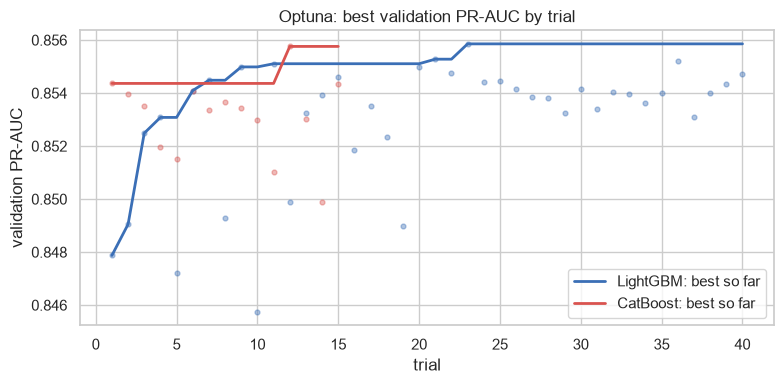

LightGBM: best trial 23 of 40; first trial 0.8479, best 0.8559, within 0.002 of best from trial 6
CatBoost: best trial 12 of 15; first trial 0.8544, best 0.8558, within 0.002 of best from trial 1


In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for st, name, c in [(st_lgb, "LightGBM", "#3b6fb6"), (st_cb, "CatBoost", "#d9534f")]:
    v = np.array([t.value for t in st.trials]); ax.plot(np.arange(1, len(v) + 1), np.maximum.accumulate(v), color=c, lw=2, label=f"{name}: best so far")
    ax.scatter(np.arange(1, len(v) + 1), v, color=c, s=12, alpha=.4)
ax.set(xlabel="trial", ylabel="validation PR-AUC", title="Optuna: best validation PR-AUC by trial"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "p3_optuna.png", dpi=120); plt.show()
for st, name in [(st_lgb, "LightGBM"), (st_cb, "CatBoost")]:
    v = np.array([t.value for t in st.trials]); best_at = int(np.argmax(v)) + 1
    print(f"{name}: best trial {best_at} of {len(v)}; first trial {v[0]:.4f}, best {v.max():.4f}, within 0.002 of best from trial {int(np.argmax(np.maximum.accumulate(v) >= v.max() - .002)) + 1}")

## 8. Одна таблица для всех моделей (тестовый период)

In [9]:
tab = pd.DataFrame({k: {c: v[c] for c in ["val PR-AUC", "test ROC-AUC", "test PR-AUC", "test F1", "fit, s", "params"]} for k, v in results.items()}).T
tab.index.names = ["model", "version"]
num_cols = ["val PR-AUC", "test ROC-AUC", "test PR-AUC", "test F1", "fit, s"]
tab[num_cols] = tab[num_cols].astype(float)
tab.to_csv(RES / "p3_models_test.csv")
tab.style.format({c: "{:.3f}" for c in num_cols[:-1]} | {"fit, s": "{:.1f}"}).background_gradient(subset=["test PR-AUC"], cmap="Greens")

In [10]:
rng = np.random.default_rng(SEED); B = [rng.integers(0, len(y_te), len(y_te)) for _ in range(1000)]
base = results[("Logistic regression", "default")]["_test"]
def gain(p):
    d = np.array([average_precision_score(y_te[i], p[i]) - average_precision_score(y_te[i], base[i]) for i in B])
    return f"{d.mean():+.3f} [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]"
ba = pd.DataFrame({fam: {"default": results[(fam, "default")]["test PR-AUC"], "tuned": results[(fam, "tuned")]["test PR-AUC"],
                         "tuning gain": results[(fam, "tuned")]["test PR-AUC"] - results[(fam, "default")]["test PR-AUC"],
                         "tuned vs logistic baseline, 95 % CI": gain(results[(fam, "tuned")]["_test"])}
                   for fam in dict.fromkeys(k[0] for k in results)}).T
ba

,default,tuned,tuning gain,"tuned vs logistic baseline, 95 % CI"
Logistic regression,0.805606,0.806197,0.000591,"+0.001 [-0.000, +0.002]"
Decision tree,0.562099,0.784318,0.222218,"-0.021 [-0.025, -0.017]"
Random forest,0.796977,0.808123,0.011145,"+0.003 [-0.001, +0.006]"
LightGBM,0.817193,0.816949,-0.000244,"+0.011 [+0.008, +0.014]"
CatBoost,0.812744,0.81495,0.002206,"+0.009 [+0.006, +0.013]"


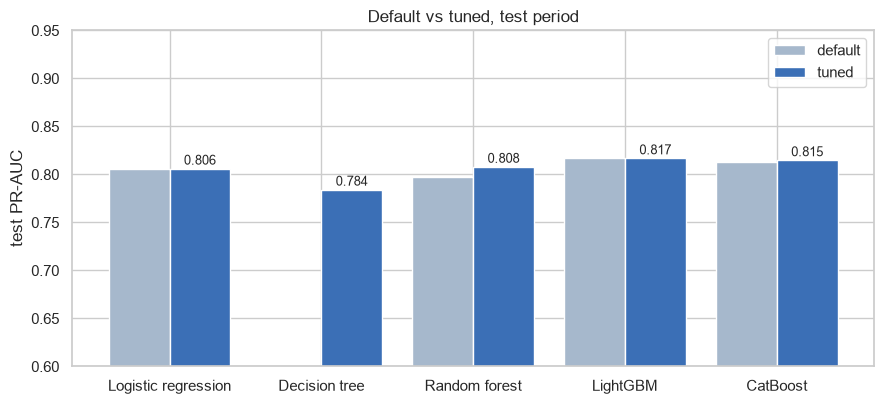

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
fams = list(dict.fromkeys(k[0] for k in results)); x = np.arange(len(fams))
ax.bar(x - .2, [results[(f, "default")]["test PR-AUC"] for f in fams], .4, label="default", color="#a6b8cc")
ax.bar(x + .2, [results[(f, "tuned")]["test PR-AUC"] for f in fams], .4, label="tuned", color="#3b6fb6")
for i, f in enumerate(fams):
    ax.text(i + .2, results[(f, "tuned")]["test PR-AUC"] + .004, f"{results[(f, 'tuned')]['test PR-AUC']:.3f}", ha="center", fontsize=9)
ax.set_xticks(x, fams); ax.set_ylim(.6, .95); ax.set(ylabel="test PR-AUC", title="Default vs tuned, test period"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "p3_before_after.png", dpi=120); plt.show()

## 9. Что важно лучшей модели — permutation importance

Permutation importance перемешивает один признак в тестовом периоде и смотрит, насколько падает PR-AUC. В отличие от
числа разбиений или gain, она показывает, что модели *нужно* на новых данных.

best model on validation: ('CatBoost', 'tuned')


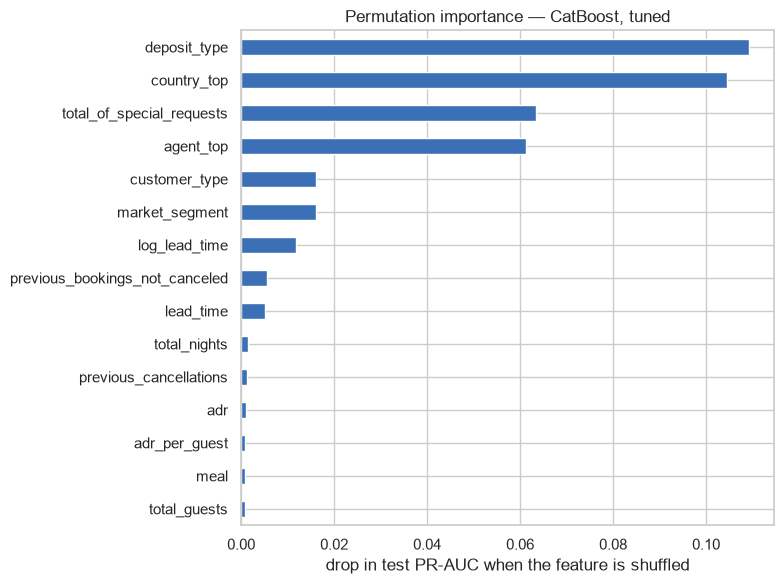

{'previous_bookings_not_canceled': 0.0054, 'log_lead_time': 0.0118, 'market_segment': 0.0161, 'customer_type': 0.0161, 'agent_top': 0.0613, 'total_of_special_requests': 0.0634, 'country_top': 0.1044, 'deposit_type': 0.1091}


In [12]:
best_key = max(results, key=lambda k: results[k]["val PR-AUC"])
print("best model on validation:", best_key)
est, Xte = (m_lgb, te[X]) if best_key[0] == "LightGBM" else (m_cb, as_cb(te)) if best_key[0] == "CatBoost" else (None, None)
if est is None:
    est, Xte = m_lgb, te[X]; print("(importance shown for tuned LightGBM)")
pi = permutation_importance(est, Xte, y_te, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X).sort_values()
fig, ax = plt.subplots(figsize=(8, 6)); imp.tail(15).plot.barh(ax=ax, color="#3b6fb6")
ax.set(xlabel="drop in test PR-AUC when the feature is shuffled", title=f"Permutation importance — {best_key[0]}, tuned"); plt.tight_layout()
plt.savefig(FIG / "p3_importance.png", dpi=120); plt.show()
print(imp.tail(8).round(4).to_dict())

## 10. Не хватает ли данных? Кривая обучения

In [13]:
lc = {}
for frac in [0.1, 0.25, 0.5, 1.0]:
    n = int(len(tr) * frac); sub = tr.iloc[-n:]                        # the most recent n training bookings
    m = lgb.LGBMClassifier(n_estimators=3000, random_state=SEED, verbose=-1, **st_lgb.best_params)
    m.fit(sub[X], sub[Y], eval_set=[(va[X], y_va)], eval_metric="average_precision", callbacks=[lgb.early_stopping(100, verbose=False)])
    lc[f"{frac:.0%} ({n:,})"] = average_precision_score(y_te, m.predict_proba(te[X])[:, 1])
pd.Series(lc, name="test PR-AUC").round(4)

10% (7,858)      0.8270
25% (19,647)     0.8173
50% (39,294)     0.8209
100% (78,589)    0.8169
Name: test PR-AUC, dtype: float64

## 11. Выводы

1. **Семейство модели важнее подбора.** Лучшее семейство — градиентный бустинг: LightGBM даёт PR-AUC на test 0,817, CatBoost
   — 0,815, логистическая регрессия — 0,806. Прирост небольшой, но надёжный (+0,011, 95 % интервал [+0,008; +0,014] у
   LightGBM). На validation и test порядок одинаков с точностью до того, что два бустинга меняются местами: бустинг >
   случайный лес ≈ логистическая регрессия > одиночное дерево.
2. **Подбор помогает там, где настройки по умолчанию плохие.** Неограниченное дерево вырастает до глубины 42 с 7 727
   листьями и запоминает train (PR-AUC на test 0,562); ограничение листа 300 бронями поднимает его до 0,784 (+0,222).
   Случайный лес получает +0,011. У логистической регрессии (+0,001), LightGBM (−0,000) и CatBoost (+0,002) настройки по
   умолчанию уже у потолка этих признаков.
3. **Optuna сходится быстро.** LightGBM был в пределах 0,002 от своего лучшего результата на validation уже с 6-й попытки
   из 40, CatBoost — с первой: байесовский поиск быстро находит хорошие области, а дальше в основном подгоняется под шум
   validation.
4. **Лучший на validation ≠ лучший на test.** У подобранного CatBoost лучший результат на validation (0,856), а на test
   лучший LightGBM с настройками по умолчанию (0,817); разница 0,002–0,003 меньше того, что может различить один период.
5. **На что опирается модель:** тип депозита и страна (каждый −0,10 PR-AUC при перемешивании), затем особые пожелания и
   турагент — то же, что было видно в EDA практики 1.
6. **Свежие данные важнее большого объёма.** Обученный только на последних 10 % train, LightGBM даёт на test 0,827 — больше,
   чем на всех 78 589 бронях (0,817). Поведение клиентов дрейфует (практика 2 показала то же), поэтому переобучение на
   свежих данных ценнее, чем добавление старых.